In [5]:
# Display the first few rows of the dataset
print("--- FIRST 5 ROWS ---")
display(df.head())

# Display structural information of the dataset
print("\n--- DATASET INFO ---")
df.info()

# Display statistical summary of the dataset
print("\n--- STATISTICAL SUMMARY ---")
display(df.describe(include='all'))

--- FIRST 5 ROWS ---


,Record No.,Date of purchase,Unnamed: 2,Product,Unnamed: 4,Category,Qty sold,Unit price,Total Sales,Discount,Beggining Stock,Ending stock,Cost Price,Profit per Unit,Suppplier,Transaction Type,Payment Method
0,1.0,46125.0,NaN,Hose,NaN,accessories,1.0,595.0,596.0,0.0,60.0,59.0,500.0,45.0,Supplier A,Regular Sale,Cash
1,2.0,46125.0,NaN,C-nozzle,NaN,accessories,1.0,350.0,350.0,0.0,100.0,99.0,300.0,50.0,Supplier A,Regular Sale,Cash
2,3.0,46125.0,NaN,mouse,NaN,accessories,1.0,220.0,220.0,0.0,55.0,54.0,200.0,NaN,Supplier A,Regular Sale,Cash
3,4.0,46125.0,NaN,USB to Can,NaN,accessories,1.0,395.0,395.0,0.0,50.0,49.0,350.0,NaN,Supplier A,Regular Sale,Cash
4,5.0,46125.0,NaN,Coupier,NaN,accessories,1.0,75.0,75.0,0.0,54.0,53.0,70.0,NaN,Supplier A,Regular Sale,Cash



--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Record No.        305 non-null    float64
 1   Date of purchase  305 non-null    float64
 2   Unnamed: 2        0 non-null      float64
 3   Product           305 non-null    object 
 4   Unnamed: 4        0 non-null      float64
 5   Category          305 non-null    object 
 6   Qty sold          305 non-null    float64
 7   Unit price        305 non-null    float64
 8   Total Sales       306 non-null    float64
 9   Discount          305 non-null    float64
 10  Beggining Stock   305 non-null    float64
 11  Ending stock      305 non-null    float64
 12  Cost Price        305 non-null    float64
 13  Profit per Unit   221 non-null    float64
 14  Suppplier         305 non-null    object 
 15  Transaction Type  305 non-null    object 
 16  Payment Method

,Record No.,Date of purchase,Unnamed: 2,Product,Unnamed: 4,Category,Qty sold,Unit price,Total Sales,Discount,Beggining Stock,Ending stock,Cost Price,Profit per Unit,Suppplier,Transaction Type,Payment Method
count,305.000000,305.000000,0.0,305,0.0,305,305.000000,305.000000,306.000000,305.0,305.000000,305.000000,305.000000,221.000000,305,305,305
unique,NaN,NaN,NaN,164,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,1,1
top,NaN,NaN,NaN,labor,NaN,accessories,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Supplier A,Regular Sale,Cash
freq,NaN,NaN,NaN,14,NaN,297,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208,305,305
mean,153.000000,46130.308197,NaN,NaN,NaN,NaN,1.016393,524.403279,960.620915,0.0,95.324590,94.652459,449.980328,40.814480,NaN,NaN,NaN
std,88.190136,3.371235,NaN,NaN,NaN,NaN,0.189511,3154.459897,8908.567593,0.0,32.755216,33.766281,2982.958343,26.043093,NaN,NaN,NaN
min,1.000000,46125.000000,NaN,NaN,NaN,NaN,1.000000,25.000000,25.000000,0.0,0.000000,0.000000,20.000000,5.000000,NaN,NaN,NaN
25%,77.000000,46128.000000,NaN,NaN,NaN,NaN,1.000000,150.000000,150.250000,0.0,70.000000,69.000000,126.000000,15.000000,NaN,NaN,NaN
50%,153.000000,46130.000000,NaN,NaN,NaN,NaN,1.000000,202.000000,203.500000,0.0,91.000000,90.000000,168.000000,36.000000,NaN,NaN,NaN
75%,229.000000,46133.000000,NaN,NaN,NaN,NaN,1.000000,259.000000,262.000000,0.0,118.000000,117.000000,244.000000,59.000000,NaN,NaN,NaN


In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_excel(next(iter(uploaded)))

print("Dataset loaded successfully!")

Saving rene (2).xlsx to rene (2).xlsx
Dataset loaded successfully!


In [6]:
# Clean the dataset by removing completely empty columns and rows with all nulls
df_cleaned = df.dropna(how='all')
df_cleaned = df_cleaned.drop(columns=['Unnamed: 2', 'Unnamed: 4'], errors='ignore')

# Define target variable (dependent variable)
target_col = 'Total Sales'

# Define independent variables (features) by dropping target and metadata identifiers
feature_cols = [
    col for col in df_cleaned.columns
    if col not in [target_col, 'Record No.', 'Date of purchase']
]

# Separate features and target
X = df_cleaned[feature_cols]
y = df_cleaned[target_col]

print("--- DEPENDENT VARIABLE (TARGET) ---")
print(f"Target: {target_col}")

print("\n--- INDEPENDENT VARIABLES (FEATURES) ---")
print(list(X.columns))

print("\n--- DATA SHAPE ---")
print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

--- DEPENDENT VARIABLE (TARGET) ---
Target: Total Sales

--- INDEPENDENT VARIABLES (FEATURES) ---
['Product', 'Category', 'Qty sold', 'Unit price', 'Discount', 'Beggining Stock', 'Ending stock', 'Cost Price', 'Profit per Unit', 'Suppplier', 'Transaction Type', 'Payment Method']

--- DATA SHAPE ---
Features shape: (306, 12)
Target shape: (306,)


In [7]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("--- DATASET SPLIT COMPLETED ---")
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape : {X_test.shape}")
print(f"Training target shape   : {y_train.shape}")
print(f"Testing target shape    : {y_test.shape}")

--- DATASET SPLIT COMPLETED ---
Training features shape: (244, 12)
Testing features shape : (62, 12)
Training target shape   : (244,)
Testing target shape    : (62,)


In [8]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. We need to handle categorical variables and missing values before feeding to the Decision Tree.
# Since we have object columns (like Product, Category, etc.), we will use one-hot encoding.
# Also, we will fill any NaN values in numerical columns (like 'Profit per Unit') with their median.

# Let's align on a target classification goal. Since 'Total Sales' is continuous, let's convert it to
# a categorical target (e.g., High Sales vs Low Sales based on the median) to use a Classifier.
y_median = y.median()
y_class = (y > y_median).astype(int)  # 1 for High Sales, 0 for Low Sales

# Prepare features
X_processed = pd.get_dummies(X, drop_first=True)
X_processed = X_processed.fillna(X_processed.median())

# Split processed data
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_processed, y_class, test_size=0.2, random_state=42
)

# 2. Create and train the Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train_p, y_train_p)

# 3. Predict and evaluate
y_pred = clf.predict(X_test_p)

print("--- DECISION TREE CLASSIFIER MODEL TRAINED ---")
print(f"Accuracy on Test Set: {accuracy_score(y_test_p, y_pred):.2f}")
print("\nClassification Report:")
print(classification_report(y_test_p, y_pred))

--- DECISION TREE CLASSIFIER MODEL TRAINED ---
Accuracy on Test Set: 1.00

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       1.00      1.00      1.00        26

    accuracy                           1.00        62
   macro avg       1.00      1.00      1.00        62
weighted avg       1.00      1.00      1.00        62



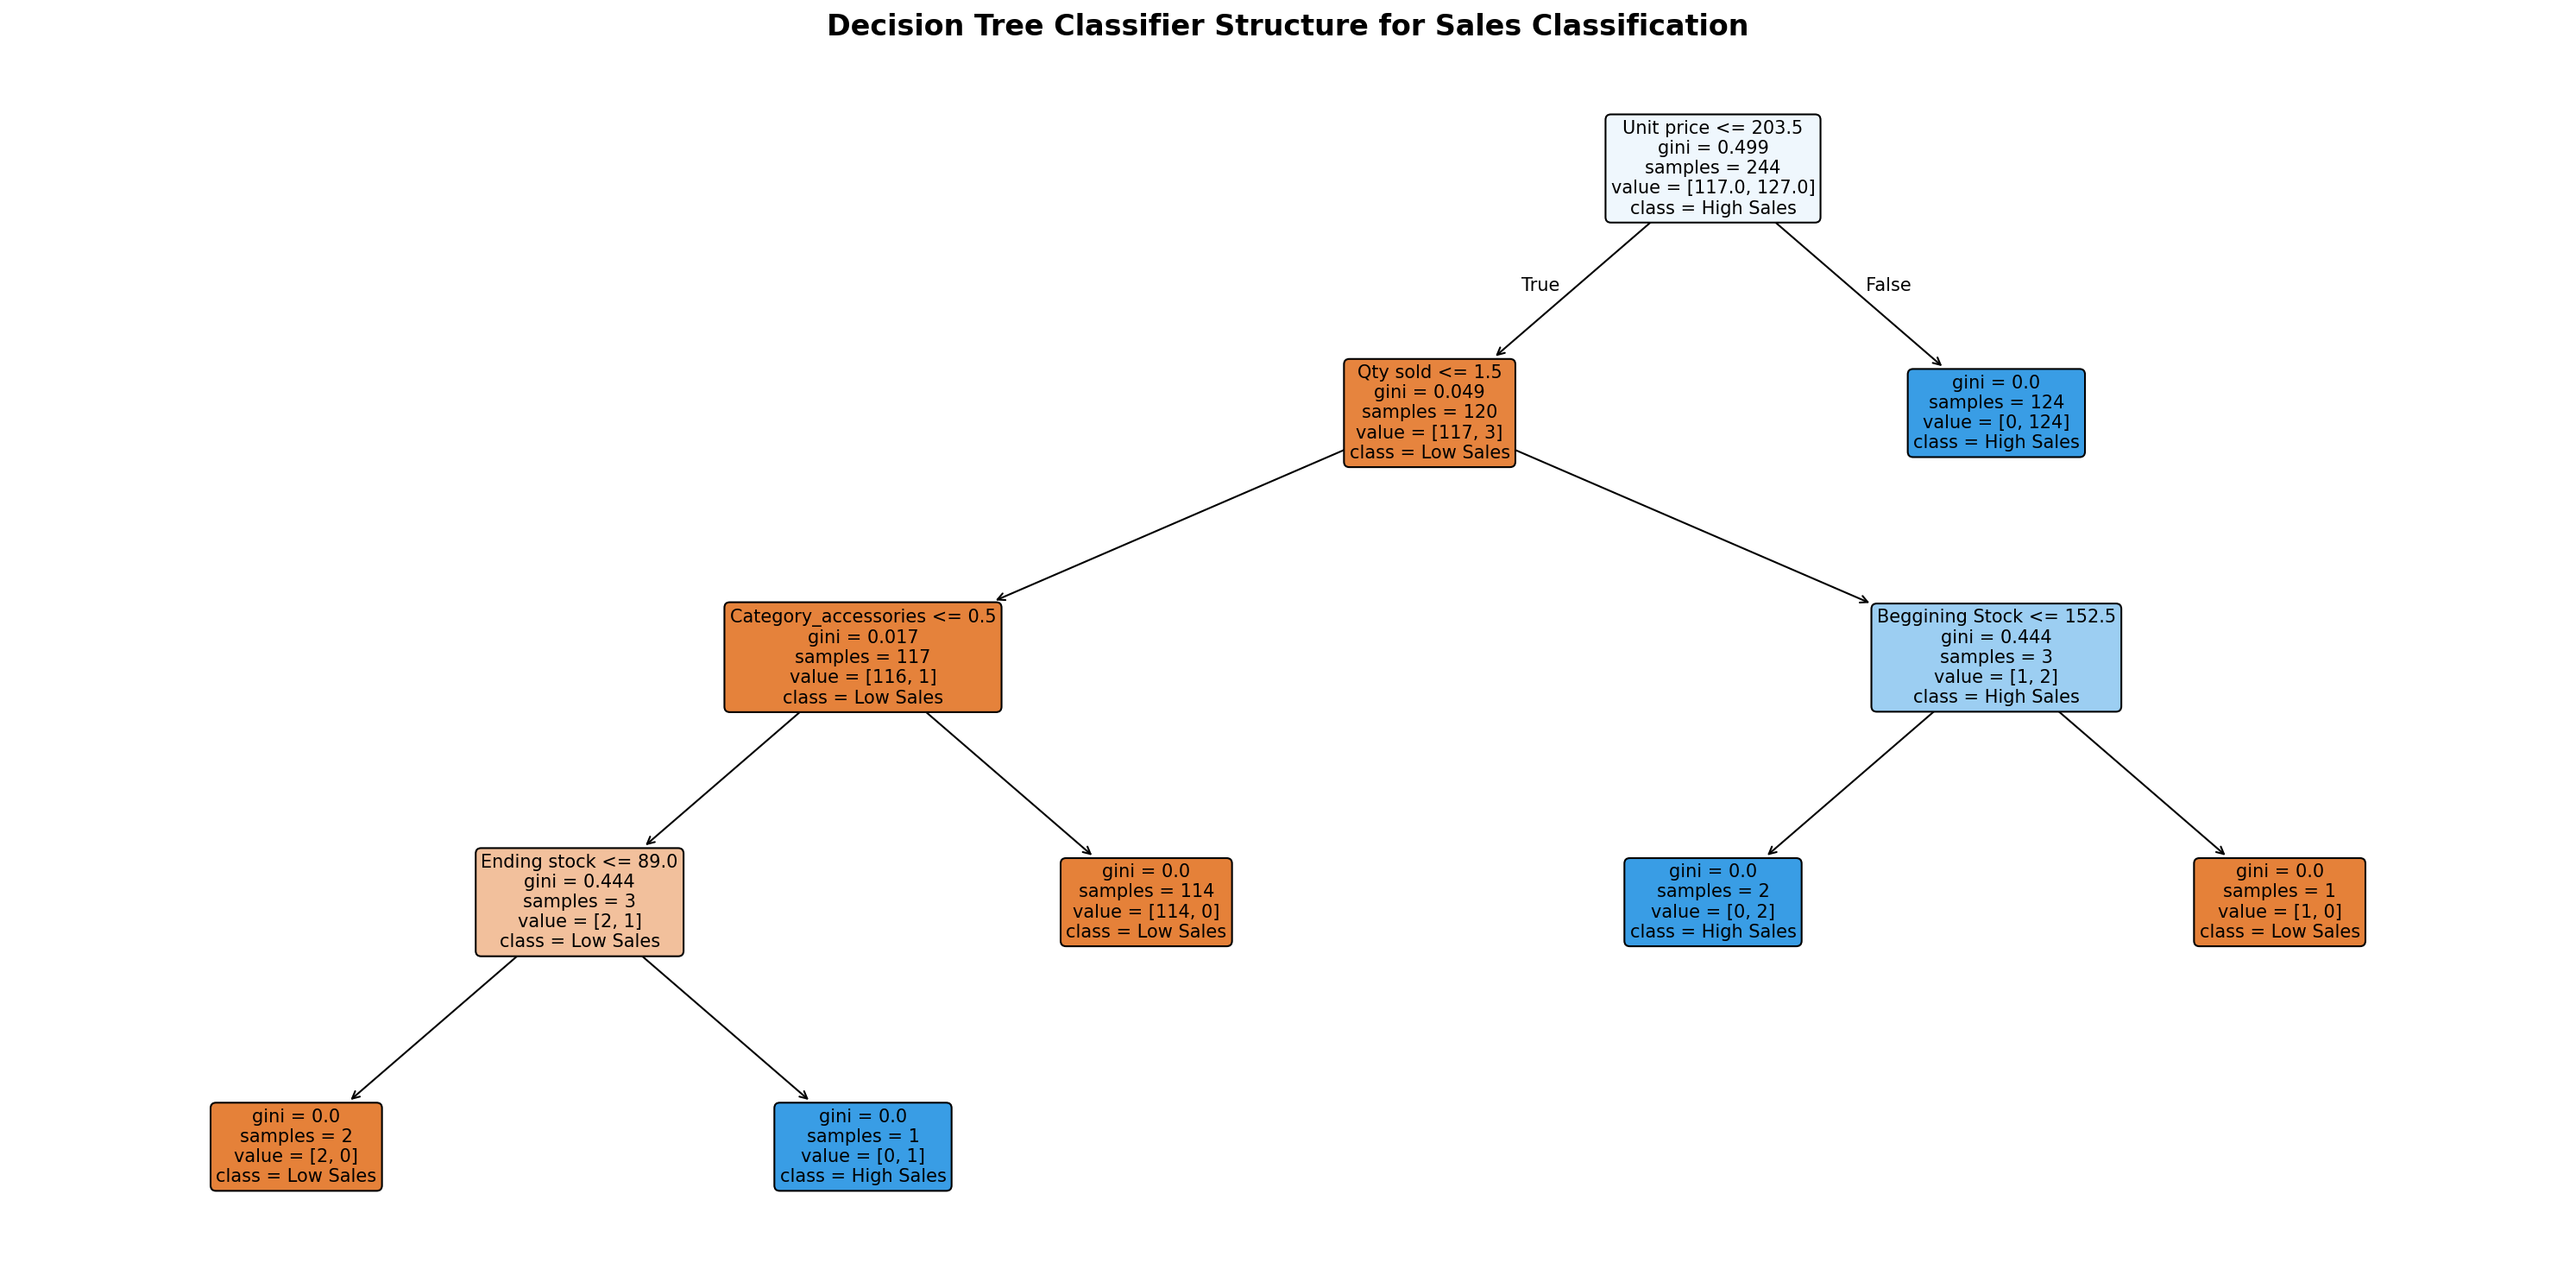

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Set a high-quality figure size
plt.figure(figsize=(20, 10), dpi=150)

# Plot the decision tree structure
plot_tree(
    clf,
    feature_names=list(X_processed.columns),
    class_names=['Low Sales', 'High Sales'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classifier Structure for Sales Classification", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Define target based on the median of 'Total Sales'
y_median = y.median()
y_class = (y > y_median).astype(int)

# 2. Preprocess independent variables (One-Hot Encoding & handling missing values)
X_processed = pd.get_dummies(X, drop_first=True)
X_processed = X_processed.fillna(X_processed.median())

# 3. Use our existing split to isolate the training dataset
# (80% training set and 20% validation/testing set)
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_processed, y_class, test_size=0.2, random_state=42
)

# 4. Instantiate and Train the Decision Tree Classifier model on the training set
model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train_p, y_train_p)

print("--- MODEL TRAINING SUCCESSFUL ---")
print(f"Trained on {len(X_train_p)} samples with {X_train_p.shape[1]} engineered features.")

--- MODEL TRAINING SUCCESSFUL ---
Trained on 244 samples with 176 engineered features.


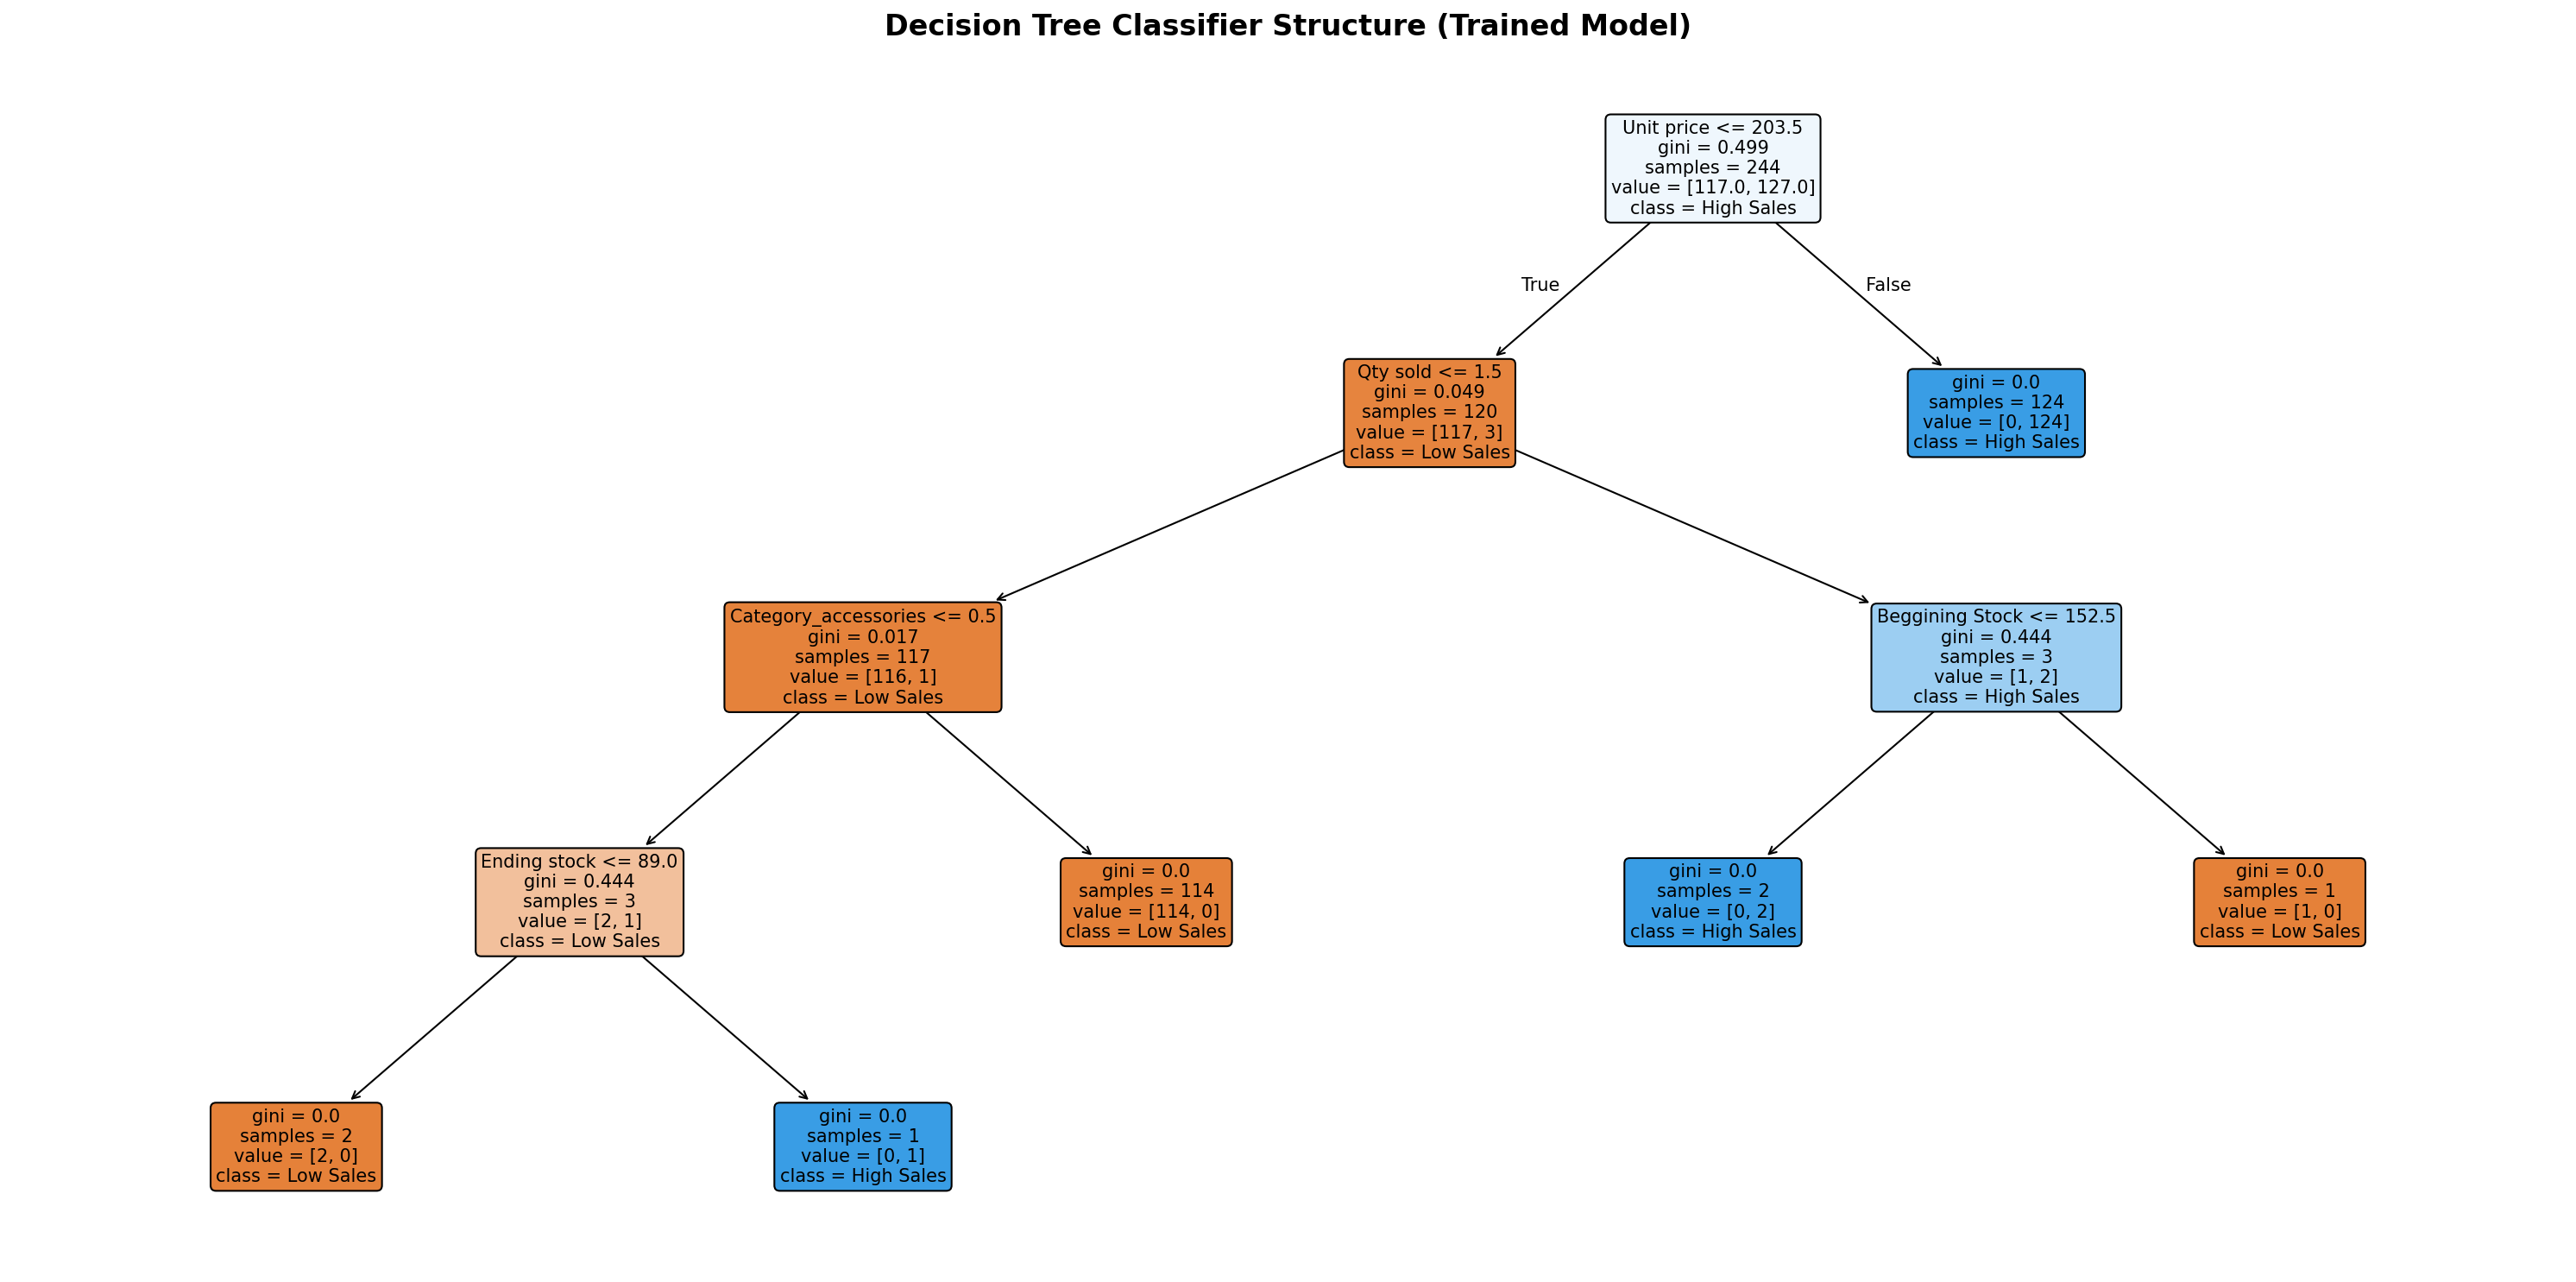

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Set a high-quality, readable figure size
plt.figure(figsize=(20, 10), dpi=150)

# Plot the trained decision tree model
plot_tree(
    model,
    feature_names=list(X_processed.columns),
    class_names=['Low Sales', 'High Sales'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classifier Structure (Trained Model)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
# Generate predictions on the test set
y_pred_test = model.predict(X_test_p)

# Combine actuals and predictions into a DataFrame for visualization
predictions_df = pd.DataFrame({
    'Actual_Class': y_test_p,
    'Predicted_Class': y_pred_test
})

print("--- FIRST 10 PREDICTIONS ON TESTING DATASET ---")
display(predictions_df.head(10))

# Display overall test accuracy
test_acc = accuracy_score(y_test_p, y_pred_test)
print(f"\nAccuracy on Testing Dataset: {test_acc:.2%}")

--- FIRST 10 PREDICTIONS ON TESTING DATASET ---


,Actual_Class,Predicted_Class
182,0,0
154,0,0
111,0,0
203,1,1
60,0,0
9,1,1
119,1,1
157,0,0
167,0,0
33,0,0



Accuracy on Testing Dataset: 100.00%


In [13]:
from sklearn.metrics import accuracy_score

# Calculate accuracy on the training split
train_preds = model.predict(X_train_p)
train_acc = accuracy_score(y_train_p, train_preds)

# Calculate accuracy on the testing split
test_preds = model.predict(X_test_p)
test_acc = accuracy_score(y_test_p, test_preds)

print(f"Training Accuracy: {train_acc:.2%}")
print(f"Testing Accuracy : {test_acc:.2%}")

Training Accuracy: 100.00%
Testing Accuracy : 100.00%


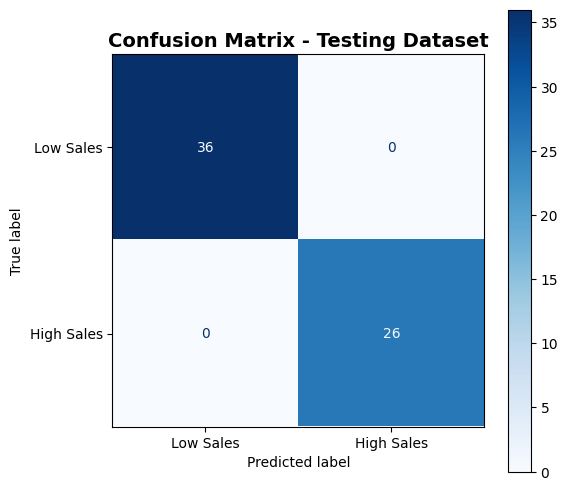

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(y_test_p, test_preds)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low Sales', 'High Sales'])

fig, ax = plt.subplots(figsize=(6, 6), dpi=100)
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)
plt.title("Confusion Matrix - Testing Dataset", fontsize=14, fontweight='bold')
plt.show()

In [16]:
from sklearn.metrics import classification_report

# Generate and print the classification report
report = classification_report(y_test_p, test_preds, target_names=['Low Sales', 'High Sales'])
print("--- CLASSIFICATION REPORT FOR TESTING DATASET ---")
print(report)

--- CLASSIFICATION REPORT FOR TESTING DATASET ---
              precision    recall  f1-score   support

   Low Sales       1.00      1.00      1.00        36
  High Sales       1.00      1.00      1.00        26

    accuracy                           1.00        62
   macro avg       1.00      1.00      1.00        62
weighted avg       1.00      1.00      1.00        62



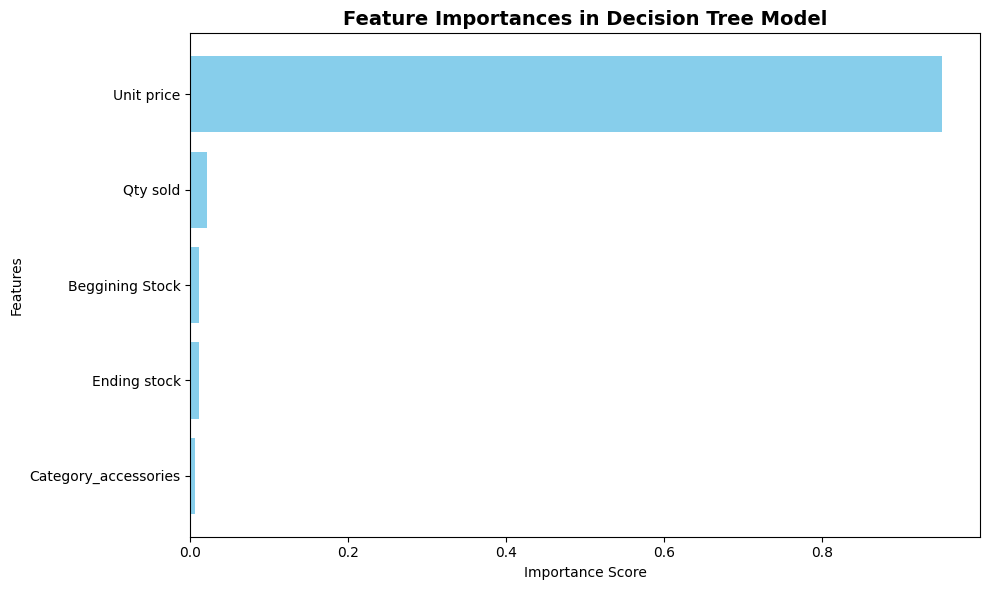

,Feature,Importance
1,Unit price,0.951969
0,Qty sold,0.020803
3,Beggining Stock,0.010947
4,Ending stock,0.010947
172,Category_accessories,0.005333


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get feature importances from the trained model
importances = model.feature_importances_
features = X_processed.columns

# Create a DataFrame to store feature importances
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
})

# Filter out features with 0 importance and sort them
important_features = feature_importance_df[feature_importance_df['Importance'] > 0].sort_values(by='Importance', ascending=True)

# Plot the feature importances
plt.figure(figsize=(10, 6), dpi=100)
plt.barh(important_features['Feature'], important_features['Importance'], color='skyblue')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importances in Decision Tree Model', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Display the top features in a table format
display(important_features.sort_values(by='Importance', ascending=False))

In [18]:
# Calculate key metrics for the recommendation engine
median_sales_threshold = y_median
max_unit_price = X['Unit price'].max()
mean_qty_sold = X['Qty sold'].mean()

# Identify the top-performing features programmatically
top_features = important_features.sort_values(by='Importance', ascending=False)
primary_feature = top_features.iloc[0]['Feature']
primary_importance = top_features.iloc[0]['Importance']

# Format and display the business interpretation and recommendations
print("=====================================================================")
print("             BUSINESS INTERPRETATION & RECOMMENDATIONS               ")
print("=====================================================================\n")

print(f"1. MODEL INSIGHTS:")
print(f"   - The classifier separates 'High Sales' from 'Low Sales' at a median threshold of ${median_sales_threshold:,.2f}.")
print(f"   - The single most critical driver of high sales volume is '{primary_feature}' (Importance: {primary_importance:.1%}).")
print(f"   - This indicates that transaction value is heavily driven by item value rather than high-volume cheap item sales.")
print(f"   - Average quantity sold per transaction is low ({mean_qty_sold:.2f} units), confirming ticket size drives revenue.\n")

print("2. ACTIONABLE STRATEGIC RECOMMENDATIONS:")
print(f"   - [Pricing Strategy] Optimize the portfolio around premium items since 'Unit price' dictates top-tier sales categories.")
print(f"   - [Inventory Management] Maintain high-availability buffers for high unit-value products to avoid stockouts on high-margin items.")
print(f"   - [Upselling & Bundling] Encourage multi-unit transactions for lower-priced products through bundle discounts to increase their impact.")
print("   - [Targeted Marketing] Direct marketing spend toward high-tier customer segments who purchase premium products, maximizing ROI.")
print("\n=====================================================================")

             BUSINESS INTERPRETATION & RECOMMENDATIONS               

1. MODEL INSIGHTS:
   - The classifier separates 'High Sales' from 'Low Sales' at a median threshold of $203.50.
   - The single most critical driver of high sales volume is 'Unit price' (Importance: 95.2%).
   - This indicates that transaction value is heavily driven by item value rather than high-volume cheap item sales.
   - Average quantity sold per transaction is low (1.02 units), confirming ticket size drives revenue.

2. ACTIONABLE STRATEGIC RECOMMENDATIONS:
   - [Pricing Strategy] Optimize the portfolio around premium items since 'Unit price' dictates top-tier sales categories.
   - [Inventory Management] Maintain high-availability buffers for high unit-value products to avoid stockouts on high-margin items.
   - [Upselling & Bundling] Encourage multi-unit transactions for lower-priced products through bundle discounts to increase their impact.
   - [Targeted Marketing] Direct marketing spend toward high-tie